# 02 - Classification on Iris

Eight classifiers on the classic 3-class flower dataset, decision boundaries in 2-D, ROC / confusion matrices, a tree you can read, and k-nearest-neighbours behaviour as k changes.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
import mlforge
from mlforge import visualization as viz
print("MLForge", mlforge.__version__)

MLForge 0.2.0


In [2]:
from sklearn.datasets import load_iris          # only used to load the data
iris = load_iris()
X, y, feats, classes = iris.data, iris.target, iris.feature_names, [str(c) for c in iris.target_names]
from mlforge.preprocessing import train_test_split, StandardScaler
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)
sc = StandardScaler().fit(Xtr); Ztr, Zte = sc.transform(Xtr), sc.transform(Xte)
print(X.shape, classes)

(150, 4) ['setosa', 'versicolor', 'virginica']


## Compare many classifiers
All fitted from scratch; cross-validated accuracy (5-fold, stratified). Note the held-out test set has only 45 flowers, so one mistake moves accuracy by 2.2 points - differences of a few points between the top models are **not significant**; the cross-validated column is the more trustworthy one.

In [3]:
from mlforge.linear_model import SoftmaxRegression, Perceptron
from mlforge.neighbors import KNeighborsClassifier
from mlforge.bayes import GaussianNB
from mlforge.tree import DecisionTreeClassifier, RandomForestClassifier, GradientBoostingClassifier
from mlforge.svm import SVC, LinearSVC
from mlforge.neural_network import MLPClassifier
from mlforge.model_selection import cross_val_score
models = {
    "Softmax regression": SoftmaxRegression(n_iters=500), "Perceptron": Perceptron(random_state=0),
    "KNN (k=5)": KNeighborsClassifier(5), "Gaussian NB": GaussianNB(),
    "Decision tree": DecisionTreeClassifier(max_depth=3), "Random forest": RandomForestClassifier(50, random_state=0),
    "Gradient boosting": GradientBoostingClassifier(60, max_depth=2, random_state=0),
    "SVM (RBF)": SVC(random_state=0), "MLP": MLPClassifier((16,), n_epochs=150, random_state=0)}
rows = []
for name, m in models.items():
    cv = cross_val_score(m, Ztr, ytr, cv=5)
    rows.append((name, cv.mean(), cv.std(), m.clone().fit(Ztr, ytr).score(Zte, yte)))
print(f"{'model':<20}{'cv acc':>10}{'+-':>8}{'test acc':>10}")
for r in sorted(rows, key=lambda r: -r[1]): print(f"{r[0]:<20}{r[1]:>10.3f}{r[2]:>8.3f}{r[3]:>10.3f}")

model                   cv acc      +-  test acc
Gaussian NB              0.981   0.023     0.911
SVM (RBF)                0.981   0.023     0.956
Decision tree            0.971   0.023     0.889
Random forest            0.971   0.023     0.889
Gradient boosting        0.971   0.023     0.911
Softmax regression       0.962   0.036     0.911
MLP                      0.962   0.036     0.911
KNN (k=5)                0.952   0.043     0.933
Perceptron               0.867   0.076     0.822


## Decision boundaries on two features
Using petal length and width (the informative pair), every model draws a different kind of boundary.

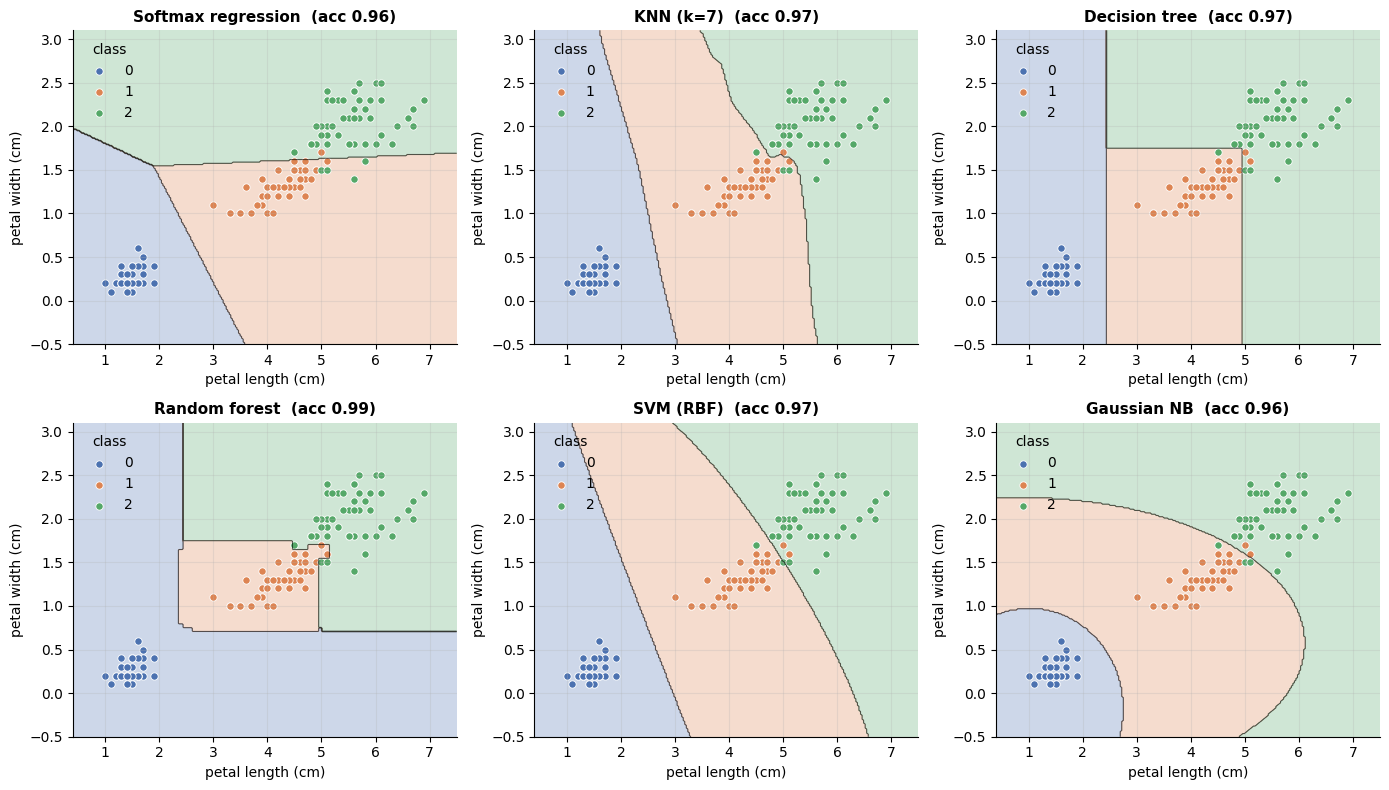

In [4]:
P = X[:, 2:4]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (name, m) in zip(axes.ravel(), {"Softmax regression": SoftmaxRegression(n_iters=800, learning_rate=0.3), "KNN (k=7)": KNeighborsClassifier(7),
        "Decision tree": DecisionTreeClassifier(max_depth=3), "Random forest": RandomForestClassifier(40, random_state=0),
        "SVM (RBF)": SVC(C=3, random_state=0), "Gaussian NB": GaussianNB()}.items()):
    m.fit(P, y); viz.plot_decision_boundary(m, P, y, ax=ax, title=f"{name}  (acc {m.score(P, y):.2f})")
    ax.set_xlabel("petal length (cm)"); ax.set_ylabel("petal width (cm)")
plt.tight_layout()

## A decision tree you can read

|--- petal length (cm) <= 2.450
|   |--- class: 0
|--- petal length (cm) >  2.450
|   |--- petal width (cm) <= 1.750
|   |   |--- petal length (cm) <= 4.950
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.950
|   |   |   |--- class: 2
|   |--- petal width (cm) >  1.750
|   |   |--- petal length (cm) <= 4.850
|   |   |   |--- class: 2
|   |   |--- petal length (cm) >  4.850
|   |   |   |--- class: 2


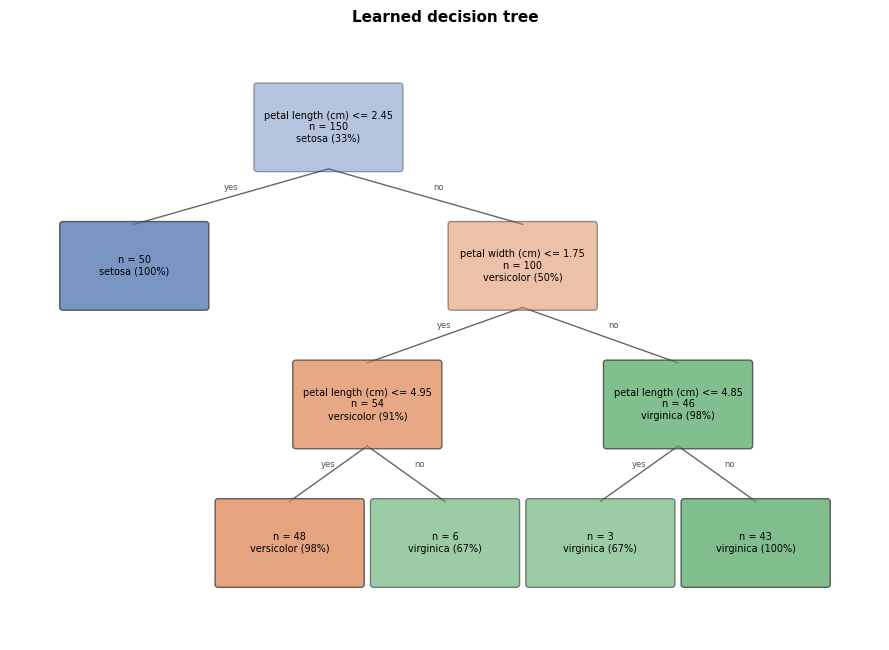

In [5]:
tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X, y)
print(tree.export_text(feats))
viz.plot_tree(tree, feats, classes);

## Evaluation: confusion matrix, per-class report, feature importance

              precision     recall   f1-score   support

           0       1.00       1.00       1.00        15
           1       0.81       0.87       0.84        15
           2       0.86       0.80       0.83        15

    accuracy                             0.89        45
   macro avg       0.89       0.89       0.89        45
weighted avg       0.89       0.89       0.89        45

out-of-bag accuracy: 0.971


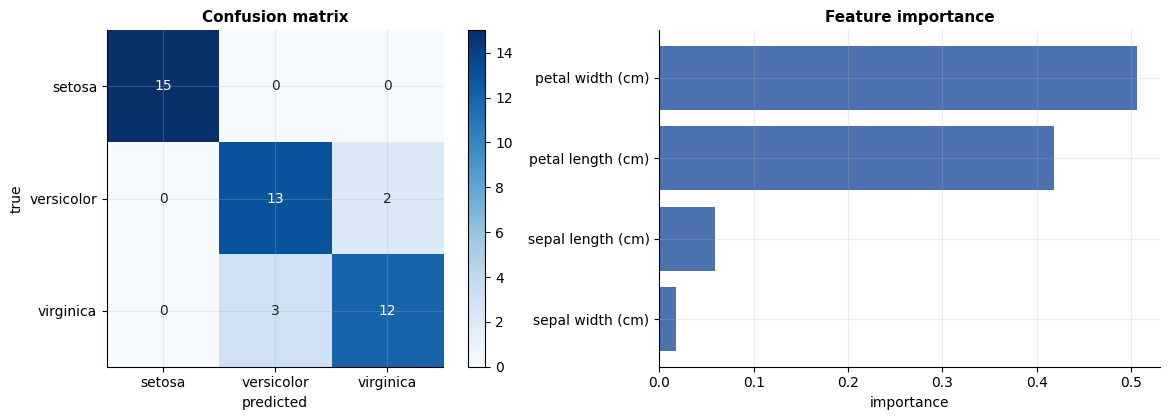

In [6]:
from mlforge.metrics import classification_report
rf = RandomForestClassifier(100, oob_score=True, random_state=0).fit(Xtr, ytr)
pred = rf.predict(Xte)
print(classification_report(yte, pred)); print("out-of-bag accuracy:", round(rf.oob_score_, 3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
viz.plot_confusion_matrix(yte, pred, labels=[0, 1, 2], ax=ax[0]); ax[0].set_xticklabels(classes); ax[0].set_yticklabels(classes)
viz.plot_feature_importance(rf.feature_importances_, feats, ax=ax[1]); plt.tight_layout()

## k in k-NN: bias vs variance
Small k memorises (jagged boundary, zero training error); large k oversmooths.

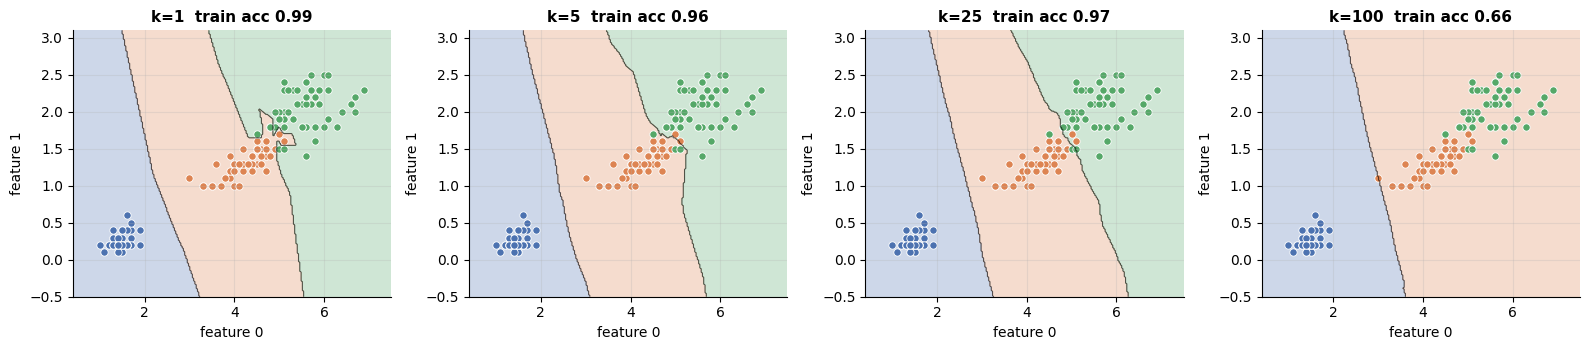

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, k in zip(axes, [1, 5, 25, 100]):
    knn = KNeighborsClassifier(k).fit(P, y); viz.plot_decision_boundary(knn, P, y, ax=ax, title=f"k={k}  train acc {knn.score(P, y):.2f}"); ax.get_legend().remove()
plt.tight_layout()